In [1]:
import warnings
warnings.filterwarnings('ignore')
import os, re, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from numba import njit, prange
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')

# Data 
DATA_START = '2000-01-01'
END_DATE = '2026-01-01'
BENCHMARK = '^SP500TR'
RF_TICKER = '^IRX' # 13-week T-bill, annualized percent
TRADING_DAYS = 252

# Rolling windows
FORMATION_MONTHS = 12 # form pairs on the first 12 months
TRADING_MONTHS = 6 # trade them on the next 6 months
STEP_MONTHS = 6 # then step forward 6 months
FIRST_FORMATION = '2000-01-01'
LAST_FORMATION = '2025-12-31'

# Pair selection 
K_OPTION = [2,4,7] # candidate cluster amounts, chosen by CVI for each window (Silhouette is the tie-breaker)
N_PAIRS = 20 # pairs traded per method

# Trading rule: following the Gatev et al. paper (2006)
ENTRY_SD = 2.0   # Open when the spread moves 2 formation-period standard deviations
LAG_DAYS = 1    # Trade the day after the signal
COST_LEVELS_BPS = [0, 5, 10, 20]

# Significance testing
N_BOOT, BLOCK_DAYS, BOOT_SEED = 5000, 20, 42

# Data Screening carried over from the first study 
KNOWN_EXCLUDE = ['FNMA', 'FMCC', 'EP', 'CCU', 'CB']

# Models 
METHODS = ['MAN', 'DTW', 'OCP', 'GATEV']
LABELS = {'MAN': 'Clustered Manhattan', 'DTW': 'Clustered DTW', 'OCP': 'Clustered OCP',
          'GATEV': 'Gatev Distance', 'Naive': 'Naive Buy-and-Hold'}
COLORS = {'MAN': '#9467bd', 'DTW': '#1f77b4', 'OCP': '#ff7f0e', 'GATEV': '#2ca02c', 'Naive': '#7f7f7f'}
PLANNED_COMPARISONS = [('MAN', 'GATEV'), ('DTW', 'MAN'), ('OCP', 'DTW')]

# Files
TAG = 'rolling_sp500'
CACHE_DIR = f'cache_{TAG}'
os.makedirs(CACHE_DIR, exist_ok=True)

print(f'Rolling design: form {FORMATION_MONTHS} months, trade {TRADING_MONTHS} months, step {STEP_MONTHS} months')
print(f'Models: {[LABELS[m] for m in METHODS]}')
print(f'Planned comparisons: {[f"{LABELS[a]} vs {LABELS[b]}" for a, b in PLANNED_COMPARISONS]}')
print(f'Cache folder: {CACHE_DIR}')

Rolling design: form 12 months, trade 6 months, step 6 months
Models: ['Clustered Manhattan', 'Clustered DTW', 'Clustered OCP', 'Gatev Distance']
Planned comparisons: ['Clustered Manhattan vs Gatev Distance', 'Clustered DTW vs Clustered Manhattan', 'Clustered OCP vs Clustered DTW']
Cache folder: cache_rolling_sp500


In [2]:
hist_url = ('https://raw.githubusercontent.com/fja05680/sp500/master/'
            'S%26P%20500%20Historical%20Components%20%26%20Changes%20(Updated).csv')
hist = pd.read_csv(hist_url)
hist['date'] = pd.to_datetime(hist['date'])
hist = hist.sort_values('date').reset_index(drop=True)
hist.to_csv(f'sp500_membership_{TAG}.csv', index=False)

suffix_pattern = re.compile(r'-\d{6}$')
def clean(t):
    return suffix_pattern.sub('', t.strip()).replace('.', '-')

def members_on(date):
    row = hist[hist['date'] <= date].iloc[-1]
    tickers = {clean(t) for t in row['tickers'].split(',')}
    return sorted(tickers - set(KNOWN_EXCLUDE))

windows = []
form_start = pd.Timestamp(FIRST_FORMATION)
last_end = pd.Timestamp(LAST_FORMATION)
while True:
    form_end  = form_start + pd.DateOffset(months=FORMATION_MONTHS) - pd.Timedelta(days=1)
    trade_start = form_end + pd.Timedelta(days=1)
    trade_end = trade_start + pd.DateOffset(months = TRADING_MONTHS) - pd.Timedelta(days=1)
    if trade_end > last_end:
        break
    windows.append({'window': len(windows) + 1,
                    'form_start': form_start, 'form_end': form_end,
                    'trade_start': trade_start, 'trade_end': trade_end,
                    'members': members_on(form_start)})
    form_start = form_start + pd.DateOffset(months=STEP_MONTHS)

window_df = pd.DataFrame(windows)
window_df['n_members'] = window_df['members'].apply(len)
print(window_df[['window', 'form_start', 'form_end', 'trade_start', 'trade_end', 'n_members']].to_string(index=False))

all_tickers = sorted(set().union(*window_df['members']))
print(f'\n{len(windows)} windows; {len(all_tickers)} distinct tickers across all windows')

with open(f'{CACHE_DIR}/windows.json','w') as f:
    json.dump([{k: (str(v.date()) if isinstance(v, pd.Timestamp) else v) for k, v in w.items()}
              for w in windows], f, indent=1)

 window form_start   form_end trade_start  trade_end  n_members
      1 2000-01-01 2000-12-31  2001-01-01 2001-06-30        487
      2 2000-07-01 2001-06-30  2001-07-01 2001-12-31        487
      3 2001-01-01 2001-12-31  2002-01-01 2002-06-30        487
      4 2001-07-01 2002-06-30  2002-07-01 2002-12-31        490
      5 2002-01-01 2002-12-31  2003-01-01 2003-06-30        491
      6 2002-07-01 2003-06-30  2003-07-01 2003-12-31        490
      7 2003-01-01 2003-12-31  2004-01-01 2004-06-30        489
      8 2003-07-01 2004-06-30  2004-07-01 2004-12-31        489
      9 2004-01-01 2004-12-31  2005-01-01 2005-06-30        489
     10 2004-07-01 2005-06-30  2005-07-01 2005-12-31        490
     11 2005-01-01 2005-12-31  2006-01-01 2006-06-30        490
     12 2005-07-01 2006-06-30  2006-07-01 2006-12-31        491
     13 2006-01-01 2006-12-31  2007-01-01 2007-06-30        492
     14 2006-07-01 2007-06-30  2007-07-01 2007-12-31        492
     15 2007-01-01 2007-12-31  2008-01-0

In [3]:
# Daily prices, benchmark and T-bill: load frozen files if they exist, otherwise download and save
PRICE_FILE = f'daily_prices_{TAG}.csv.gz'
BENCH_FILE = f'bench_daily_{TAG}.csv'
RF_FILE = f'rf_daily_{TAG}.csv'

def to_close_frame(raw):
    close = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]
    return close if isinstance(close, pd.DataFrame) else close.to_frame()

if os.path.exists(PRICE_FILE):
    prices = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True)
    print(f'Loaded frozen prices from {PRICE_FILE}')
else: 
    raw = yf.download(all_tickers, start=DATA_START, end=END_DATE, interval='1d',
                      auto_adjust=True, progress=True, threads=True)
    prices = to_close_frame(raw).dropna(how='all')   #drop days with no data
    prices = prices.dropna(axis=1, how='all')
    prices.to_csv(PRICE_FILE, float_format='%.6f')
    print(f'Downloaded and saved prices to {PRICE_FILE}')

missing = sorted(set(all_tickers) - set(prices.columns))
print(f'Tickers with data: {prices.shape[1]} of {len(all_tickers)} ({len(missing)} with none)')
print(f'Date range: {prices.index[0].date()} to {prices.index[-1].date()} ({len(prices):,} trading days)')
print('Sanity check, large current stock present:',
      {t: t in prices.columns for t in ['AAPL', 'MSFT', 'JPM', 'XOM', 'JNJ']})   

# Benchmark (context only)
if os.path.exists(BENCH_FILE):
    bench = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0]
else:
    b = to_close_frame(yf.download(BENCHMARK, start=DATA_START, end=END_DATE, interval='1d',
                                   auto_adjust=True, progress=False))
    bench = b.iloc[:,0].reindex(prices.index)
    print(f'Benchmark missing days before filling: {int(bench.isna().sum())}')
    bench = bench.ffill()
    bench.to_csv(BENCH_FILE)

# Daily risk-free rate, known at the start of each day
if os.path.exists(RF_FILE):
    rf_daily = pd.read_csv(RF_FILE, index_col=0, parse_dates=True).iloc[:, 0]
else:
    i = to_close_frame(yf.download(RF_TICKER, start=DATA_START, end=END_DATE, interval='1d',
                                   auto_adjust=False, progress=False))
    irx = i.iloc[:, 0].reindex(prices.index).ffill().bfill()
    rf_daily = (np.log1p(irx / 100) / TRADING_DAYS).shift(1).bfill()
    rf_daily.to_csv(RF_FILE)
    print(f'T-bill mean annual yield: {irx.mean():.2f}%')

$JOY: possibly delisted; no timezone found
$CTLT: possibly delisted; no timezone found      ]
[                       0%                       ]  2 of 1047 completed$ATVI: possibly delisted; no timezone found
$WLL: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: AWE"}}}
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: OWENQ"}}}
$AWE: possibly delisted; no timezone found
$MOLX: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "No data found, symbol may be delisted")
[                       1%                       ]  6 of 1047 completed$OWENQ: possibly delisted; no timezone found
[                       1%                       ]  6 of 1047 completed$BMS: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "No data found, symbol may be delisted")

Downloaded and saved prices to daily_prices_rolling_sp500.csv.gz
Tickers with data: 647 of 1047 (400 with none)
Date range: 2000-01-03 to 2025-12-31 (6,539 trading days)
Sanity check, large current stock present: {'AAPL': True, 'MSFT': True, 'JPM': True, 'XOM': True, 'JNJ': True}


In [6]:
orig_url = ('https://raw.githubusercontent.com/fja05680/sp500/master/'
            'S%26P%20500%20Historical%20Components%20%26%20Changes.csv')
ORIG_FILE = f'sp500_membership_original_{TAG}.csv'
if os.path.exists(ORIG_FILE):
    orig = pd.read_csv(ORIG_FILE, parse_dates=['date'])
else:
    orig = pd.read_csv(orig_url)
    orig['date'] = pd.to_datetime(orig['date'])
    orig = orig.sort_values('date').reset_index(drop=True)
    orig.to_csv(ORIG_FILE, index=False)

def reused_in_window(form_start):
    if form_start > orig['date'].max():
        return set()                                   # no delisting markers after 2019
    row = orig[orig['date'] <= form_start].iloc[-1]
    raw = [t.strip() for t in row['tickers'].split(',')]
    plain = {clean(t) for t in raw if not suffix_pattern.search(t)}
    reused = set()
    for t in raw:
        if suffix_pattern.search(t):
            c = clean(t)
            d = pd.Timestamp(f'{t[-6:-2]}-{t[-2:]}-01') + pd.offsets.MonthEnd(0)
            if c not in plain and c in prices.columns:
                if prices.loc[d + pd.Timedelta(days=31):, c].notna().any():
                    reused.add(c)
    return reused

# 2. Per-window universe, including the reused-ticker rule
def window_universe(form_start, form_end):
    row = hist[hist['date'] <= form_start].iloc[-1]
    members = {clean(t) for t in row['tickers'].split(',')} - set(KNOWN_EXCLUDE) - otc
    reused = reused_in_window(form_start)
    form = prices.loc[form_start:form_end]
    with_data = [t for t in members if t in form.columns]
    complete = [t for t in with_data if form[t].notna().all()]
    usable = [t for t in complete if t not in reused]
    return sorted(usable), len(members), len(with_data), len(complete) - len(usable)

summary = []
for w in windows:
    usable, n_mem, n_data, n_reused = window_universe(w['form_start'], w['form_end'])
    w['universe'] = usable
    summary.append({'window': w['window'], 'form_start': w['form_start'].date(),
                    'members': n_mem, 'with_data': n_data,
                    'reused_removed': n_reused, 'usable': len(usable)})
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))
summary_df.to_csv(f'universe_by_window_{TAG}.csv', index=False)
with open(f'{CACHE_DIR}/universes.json', 'w') as f:
    json.dump({str(w['window']): w['universe'] for w in windows}, f)
print(f"\nUsable stocks per window: min {summary_df['usable'].min()}, "
      f"median {int(summary_df['usable'].median())}, max {summary_df['usable'].max()}")

 window form_start  members  with_data  reused_removed  usable
      1 2000-01-01      486        275               3     221
      2 2000-07-01      486        277               2     224
      3 2001-01-01      487        285               2     232
      4 2001-07-01      490        289               2     236
      5 2002-01-01      491        288               3     237
      6 2002-07-01      490        292               4     239
      7 2003-01-01      489        297               3     245
      8 2003-07-01      489        299               3     247
      9 2004-01-01      489        300               4     248
     10 2004-07-01      490        299               4     251
     11 2005-01-01      490        298               4     251
     12 2005-07-01      491        299               4     252
     13 2006-01-01      492        306               4     263
     14 2006-07-01      492        312               4     269
     15 2007-01-01      492        314               5 

In [12]:
# Formation-year inputs and the Manhattan distance (no warping)
def formation_paths(w):
    px = prices.loc[w['form_start']:w['form_end'], w['universe']]
    X = (px/px.iloc[0] - 1.0).values.astype(np.float64)  # cumulative returns from day 1, starts at 0
    return X, list(px.columns)

@njit(parallel=True, cache=True)
def manhattan_matrix(X):
    T, n = X.shape
    D = np.zeros((n,n))
    for i in prange(n):
        for j in range(i + 1, n):
            s = 0.0
            for t in range(T):
                s += abs(X[t,i] - X[t,j])
            D[i, j] = s
            D[j, i] = s
    return D

# Sanity check on window 1
X1, tick1 = formation_paths(windows[0])
t0 = time.time()
D_man1 = manhattan_matrix(X1)
print(f'Window 1: {X1.shape[1]} stocks, {X1.shape[0]} formation days, '
      f'Manhattan matrix {D_man1.shape} in {time.time()-t0:.2f}s')
print(f'Symmetric: {np.allclose(D_man1, D_man1.T)}, zero diagonal: {np.all(np.diag(D_man1) == 0)}')
i, j = np.unravel_index(np.argmin(D_man1 + np.eye(len(tick1)) * 1e9), D_man1.shape)
print(f'Closest pair in window 1: {tick1[1]}-{tick1[j]} (distance {D_man1[i,j]:.2f})')

Window 1: 221 stocks, 252 formation days, Manhattan matrix (221, 221) in 1.50s
Symmetric: True, zero diagonal: True
Closest pair in window 1: ABT-OMC (distance 10.25)


In [18]:
# DTW distance: same absolute-difference cost as Manhattan, but any warping path is allowed
@njit(cache=True)
def dtw_abs(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(m):
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def dtw_matrix(X):
    T, n = X.shape
    D = np.zeros((n,n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = dtw_abs(X[:, i], X[:, j])
            D[i, j] = d
            D[j, i] = d
    return D

# Sanity check on window 1
t0 = time.time()
D_dtw1 = dtw_matrix(X1)
print(f'DTW  matrix:{D_dtw1.shape} in {time.time()-t0:.2f}s')
print(f'Symmetric: {np.allclose(D_dtw1, D_dtw1.T)}, zero diagonal: {np.all(np.diag(D_dtw1) == 0)}')
print(f'DTW never exceeds Manhattan: {np.all(D_dtw1 <= D_man1 + 1e-9)}')
iu = np.triu_indices(len(tick1), k=1)
print(f'Average DTW / Manhattan ratio: {np.mean(D_dtw1[iu] / D_man1[iu]):.3f}')
i, j = np.unravel_index(np.argmin(D_dtw1 + np.eye(len(tick1)) * 1e9), D_dtw1.shape)
print(f'Closest pair in window 1: {tick1[i]}-{tick1[j]} (distance: {D_dtw1[i, j]:.2f})')

DTW  matrix:(221, 221) in 6.98s
Symmetric: True, zero diagonal: True
DTW never exceeds Manhattan: True
Average DTW / Manhattan ratio: 0.651
Closest pair in window 1: ECL-ITT (distance: 4.18)


In [19]:
# OCP distance: DTW restricted to causal paths (j >= i), computed in both directions, smaller kept 
@njit(cache=True)
def ocp_one_way(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(i, m):              # OCP: only j >= i (causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def ocp_matrix(X):
    T, n = X.shape
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = min(ocp_one_way(X[:, i], X[:, j]), ocp_one_way(X[:, j], X[:, i]))
            D[i, j] = d
            D[j, i] = d
    return D

# Sanity check on window 1
t0 = time.time()
D_ocp1 = ocp_matrix(X1)
print(f'OCP matrix {D_ocp1.shape} in {time.time()-t0:.2f}s')
print(f'Symmetric: {np.allclose(D_ocp1, D_ocp1.T)}, zero diagonal: {np.all(np.diag(D_ocp1) == 0)}')
print(f'DTW <= OCP: {np.all(D_dtw1 <= D_ocp1 + 1e-9)}')
print(f'OCP <= Manhattan: {np.all(D_ocp1 <= D_man1 + 1e-9)}')
print(f'Average OCP/ Manhattan ratio: {np.mean(D_ocp1[iu] / D_man1[iu]):.3f}')
i, j = np.unravel_index(np.argmin(D_ocp1 + np.eye(len(tick1)) * 1e9), D_ocp1.shape)
print(f'Closest pair in window 1: {tick1[i]}-{tick1[j]} (distance {D_ocp1[i, j]:.2f})')

OCP matrix (221, 221) in 8.14s
Symmetric: True, zero diagonal: True
DTW <= OCP: True
OCP <= Manhattan: True
Average OCP/ Manhattan ratio: 0.677
Closest pair in window 1: ECL-ITT (distance 4.53)


In [27]:
# Ward clustering with k chosen per window by majority vote of three indices (silhouette breaks ties)
def cluster_and_choose_k(D, X):
    link = linkage(squareform(D, checks=False), method='ward')
    feats = X.T
    rows, labels = [], {}
    for k in K_OPTION:
        lab = fcluster(link, t=k, criterion='maxclust')
        labels[k] = lab
        rows.append({'k': k,
                     'silhouette': silhouette_score(D, lab, metric='precomputed'),
                     'calinski-harabasz': calinski_harabasz_score(feats, lab),
                     'davies_bouldin': davies_bouldin_score(feats, lab)})
        scores = pd.DataFrame(rows).set_index('k')
        votes = {'silhouette': int(scores['silhouette'].idxmax()),
                 'calinski-harabasz': int(scores['calinski-harabasz'].idxmax()),
                 'davies_bouldin': int(scores['davies_bouldin'].idxmin())}
        counts = pd.Series(list(votes.values())).value_counts()
        k = int(counts.index[0]) if counts.iloc[0] >=  2 else votes['silhouette']
        agree = int(counts.iloc[0])
        return labels[k], k, agree, votes, scores

# Sanity check on window 1
for name, D in [('MAN', D_man1), ('DTW', D_dtw1), ('OCP', D_ocp1)]:
    lab, k, agree, votes, scores = cluster_and_choose_k(D, X1)
    sizes = sorted(np.bincount(lab)[1:], reverse=True)
    print(f'{name}: choose k={k} ({agree} of 3 agreed), votes {votes}, cluster sizes {sizes}')

MAN: choose k=2 (3 of 3 agreed), votes {'silhouette': 2, 'calinski-harabasz': 2, 'davies_bouldin': 2}, cluster sizes [np.int64(111), np.int64(110)]
DTW: choose k=2 (3 of 3 agreed), votes {'silhouette': 2, 'calinski-harabasz': 2, 'davies_bouldin': 2}, cluster sizes [np.int64(121), np.int64(100)]
OCP: choose k=2 (3 of 3 agreed), votes {'silhouette': 2, 'calinski-harabasz': 2, 'davies_bouldin': 2}, cluster sizes [np.int64(123), np.int64(98)]


In [29]:
# Pair selection: top 20 pairs within clusters for MAN/DTW/OCP, top 20 by SSD for Gatev
def top_pairs(D, n_pairs, mask=None):
    n = D.shape[0]
    iu = np.triu_indices(n, k=1)
    d = D[iu]
    order = np.argsort(d, kind='stable')
    if mask is None:
        chosen = order[:n_pairs]
    else:
        m = mask[iu]
        inside = order[m[order]]
        outside = order[~m[order]]
        chosen = np.concatenate([inside[:n_pairs], outside[:max(0, n_pairs - len(inside))]])
    return [(int(iu[0][c]), int(iu[1][c]), float(d[c])) for c in chosen]

def clustered_pairs(D, labels, tickers, n_pairs=N_PAIRS):
    same = labels[:, None] == labels[None,:]
    chosen = top_pairs(D, n_pairs, mask=same)
    unrestricted = {(i, j) for i, j, _ in top_pairs(D, n_pairs)}
    overlap = sum((i,j) in unrestricted for i, j, _ in chosen)
    return [(tickers[i], tickers[j], d) for i, j, d in chosen], overlap

def gatev_pairs(X, tickers, n_pairs=N_PAIRS):
    G = X.T @ X
    sq = np.diag(G)
    SSD = sq[:, None] + sq[None, :] - 2 * G
    chosen = top_pairs(SSD, n_pairs)
    return [(tickers[i], tickers[j], d) for i, j, d in chosen], SSD

# Sanity check on window 1
lab_dtw1, *_ = cluster_and_choose_k(D_dtw1, X1)
p_dtw1, ov = clustered_pairs(D_dtw1, lab_dtw1, tick1)
p_gat1, SSD1 = gatev_pairs(X1, tick1)
print('DTW top 5:', [(a, b, round(d, 2)) for a,b, d in p_dtw1[:5]])
print(f'DTW pairs also in its unclustered top 20: {ov} of {N_PAIRS}')
print('Gatev top 5:', [(a, b, round(d,  2)) for a, b, d in p_gat1[:5]])
print('SSD matches the direct sum of squared gaps:',
      bool(np.isclose(SSD1[0, 1], ((X1[:, 0] - X1[:, 1]) ** 2).sum())))
shared = {frozenset(p[:2]) for p in p_dtw1} & {frozenset(p[:2]) for p in p_gat1}
print(f'Pairs chosen by both DTW and Gatev: {len(shared)} of {N_PAIRS}')


DTW top 5: [('ECL', 'ITT', 4.18), ('ECL', 'UNP', 4.21), ('ECL', 'ED', 4.28), ('BF-B', 'ED', 4.5), ('AVY', 'PPG', 4.62)]
DTW pairs also in its unclustered top 20: 20 of 20
Gatev top 5: [('DLX', 'OMC', 0.69), ('DDS', 'WOR', 0.74), ('ECL', 'ED', 0.75), ('DLX', 'ITW', 0.78), ('CAT', 'MAS', 0.8)]
SSD matches the direct sum of squared gaps: True
Pairs chosen by both DTW and Gatev: 9 of 20


In [30]:
# Gatev et al. (2006) trading rule for one pair over one 6-month trading period
def trade_pair(s1, s2, w, cost_bps=0.0):
    form = prices.loc[w['form_start']:w['form_end'], [s1, s2]]
    nf = form / form.iloc[0]
    sigma = (nf[s1] - nf[s2]).std()    # spread volatility from the formation year

    px = prices.loc[w['trade_start']:w['trade_end'], [s1, s2]]
    valid = px.notna().all(axis=1)
    if len(px) == 0 or not valid.iloc[0]:
        return px.Series(0.0, index=pd.index), 0
    alive = valid.cummin()
    px = px.ffill()
    nt = px / px.iloc[0]
    spread = (nt[s1] - nt[s2]).values

    # Using Gatev's trading rules
    sig = np.zeros(len(spread))
    pos = 0
    for t in range(len(spread)):
        if not alive.iloc[t]:
            pos = 0
        elif pos == 0:
            if spread[t] > ENTRY_SD * sigma:
                pos = -1                        # s1 ran ahead: short s1, long s2
            elif spread[t] < -ENTRY_SD * sigma:
                pos = 1                         # s1 fell behind: long s1, short s2
        elif pos == -1 and spread[t] <= 0:
                pos = 0                         # prices crossed: close
        elif pos == 1 and spread[t] >= 0:
                pos = 0
        sig[t] = pos

    sig = pd.Series(sig, index=px.index)
    held = sig.shift(1 + LAG_DAYS).fillna(0)   # trade signal at close t, close trade at t+1
    held.iloc[-1] = 0                          # close anything still open at period end
    r = px.pct_change().fillna(0)
    gross = held * (r[s1] - r[s2]) / 2      # per one dollar of gross exposure
    cost = held.diff().abs().fillna(held.abs()) * cost_bps / 10000
    n_trades = int((held.diff().abs() > 0).sum() // 2)
    return np.log1p(gross - cost), n_trades

# Quick check on DTW's closest pair in window 1 using 10 as transaction cost
s1, s2 = p_dtw1[0][:2]
r0, n0 = trade_pair(s1, s2, windows[0])
r10, _ = trade_pair(s1, s2, windows[0], cost_bps=10)
print(f'{s1}-{s2}, Jan-Jun 2001: {n0} round trips, {int((r0 != 0).sum())} days with a position')
print(f'Total log return: {r0.sum():.4f} at 0 bps, {r10.sum():.4f} at 10 bps')

ECL-ITT, Jan-Jun 2001: 1 round trips, 111 days with a position
Total log return: -0.0684 at 0 bps, -0.0704 at 10 bps


In [33]:
# Main loop: for each window, compute distances, cluster, select pairs and trade them, with caching
def run_window(w):
    n = w['window']
    sel_file = f'{CACHE_DIR}/selection_w{n:02d}.json'
    ret_file = f'{CACHE_DIR}/returns_w{n:02d}.csv'
    if os.path.exists(sel_file) and os.path.exists(ret_file):
        with open(sel_file) as f:
            sel = json.load(f)
        return sel, pd.read_csv(ret_file, index_col=0, parse_dates=True)

    X, tickers = formation_paths(w)
    sel = {'window': n, 'n_stocks': len(tickers)}
    for m, dist in {'MAN': manhattan_matrix, 'DTW': dtw_matrix, 'OCP': ocp_matrix}.items():
        dfile = f'{CACHE_DIR}/dist_{m}_w{n:02d}.npy'
        if os.path.exists(dfile):
            D = np.load(dfile)
        else:
            D = dist(X)
            np.save(dfile, D)
        lab, k, agree, votes, _ = cluster_and_choose_k(D, X)
        pairs, overlap = clustered_pairs(D, lab, tickers)
        sel[m] = {'pairs': [[a, b] for a, b, _ in pairs], 'k': k, 'agree': agree,
                  'votes': votes, 'overlap': overlap}
    g_pairs, _ = gatev_pairs(X, tickers)
    sel['GATEV'] = {'pairs': [[a, b] for a, b, _ in g_pairs]}

    cols = {}
    for m in METHODS:
        sel[m]['round_trips'] = 0
        for c in COST_LEVELS_BPS:
            rets = []
            for a, b in sel[m]['pairs']:
                r, nt = trade_pair(a, b, w, cost_bps=c)
                rets.append(np.expm1(r))
                if c == 0:
                    sel[m]['round_trips'] += nt
            cols[f'{m}_{c}'] = np.log1p(pd.concat(rets, axis=1).mean(axis=1))
    ret = pd.DataFrame(cols)
    with open(sel_file, 'w') as f:
        json.dump(sel, f)
    ret.to_csv(ret_file)
    return sel, ret

RUN = windows   # test run on all 50 trading windows
selections, returns = {}, {}
t_all = time.time()
for w in RUN:
    t0 = time.time()
    sel, ret = run_window(w)
    selections[w['window']], returns[w['window']] = sel, ret
    totals = ' '.join(f"{m} {ret[f'{m}_0'].sum():+.3f}" for m in METHODS)
    print(f"Window {w['window']:2d} ({w['trade_start'].date()} to {w['trade_end'].date()}): "
          f"{sel['n_stocks']} stocks | k MAN/DTW/OCP = {sel['MAN']['k']}/{sel['DTW']['k']}/{sel['OCP']['k']} | "
          f"round trips  " + '/'.join(str(sel[m]['round_trips']) for m in METHODS) +
          f" | 0 bps log return: {totals} | {time.time()-t0:.0f}s")
print(f'Done in {time.time()-t_all:.0f}s')    

Window  1 (2001-01-01 to 2001-06-30): 221 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  27/27/26/26 | 0 bps log return: MAN -0.012 DTW +0.014 OCP -0.010 GATEV -0.011 | 0s
Window  2 (2001-07-01 to 2001-12-31): 224 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  24/22/18/24 | 0 bps log return: MAN +0.029 DTW +0.031 OCP +0.036 GATEV +0.033 | 0s
Window  3 (2002-01-01 to 2002-06-30): 232 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  30/26/21/30 | 0 bps log return: MAN -0.015 DTW +0.006 OCP -0.009 GATEV -0.002 | 0s
Window  4 (2002-07-01 to 2002-12-31): 236 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  32/25/27/33 | 0 bps log return: MAN +0.031 DTW +0.029 OCP +0.018 GATEV +0.022 | 14s
Window  5 (2003-01-01 to 2003-06-30): 237 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  27/29/23/28 | 0 bps log return: MAN -0.012 DTW +0.000 OCP +0.006 GATEV -0.000 | 17s
Window  6 (2003-07-01 to 2003-12-31): 239 stocks | k MAN/DTW/OCP = 2/2/2 | round trips  23/22/17/24 | 0 bps log return: MAN +0.011 DTW +0.024 O

Stitched returns: 6,287 trading days, 2001-01-02 to 2025-12-31
 cost_bps               model  ann_return  ann_vol  sharpe  sortino  max_drawdown  calmar  total_log_return
   0.0000 Clustered Manhattan      0.0014   0.0246  0.0557   0.0818       -0.1516  0.0090            0.0342
   0.0000       Clustered DTW      0.0052   0.0236  0.2190   0.3320       -0.1084  0.0478            0.1292
   0.0000       Clustered OCP      0.0012   0.0241  0.0507   0.0734       -0.1289  0.0095            0.0304
   0.0000      Gatev Distance      0.0049   0.0234  0.2110   0.3120       -0.0917  0.0540            0.1234
  10.0000 Clustered Manhattan     -0.0038   0.0246 -0.1560  -0.2271       -0.1820 -0.0211           -0.0959
  10.0000       Clustered DTW      0.0002   0.0237  0.0064   0.0096       -0.1609  0.0009            0.0038
  10.0000       Clustered OCP     -0.0035   0.0241 -0.1455  -0.2090       -0.1598 -0.0219           -0.0875
  10.0000      Gatev Distance     -0.0004   0.0235 -0.0160  -0.0234      

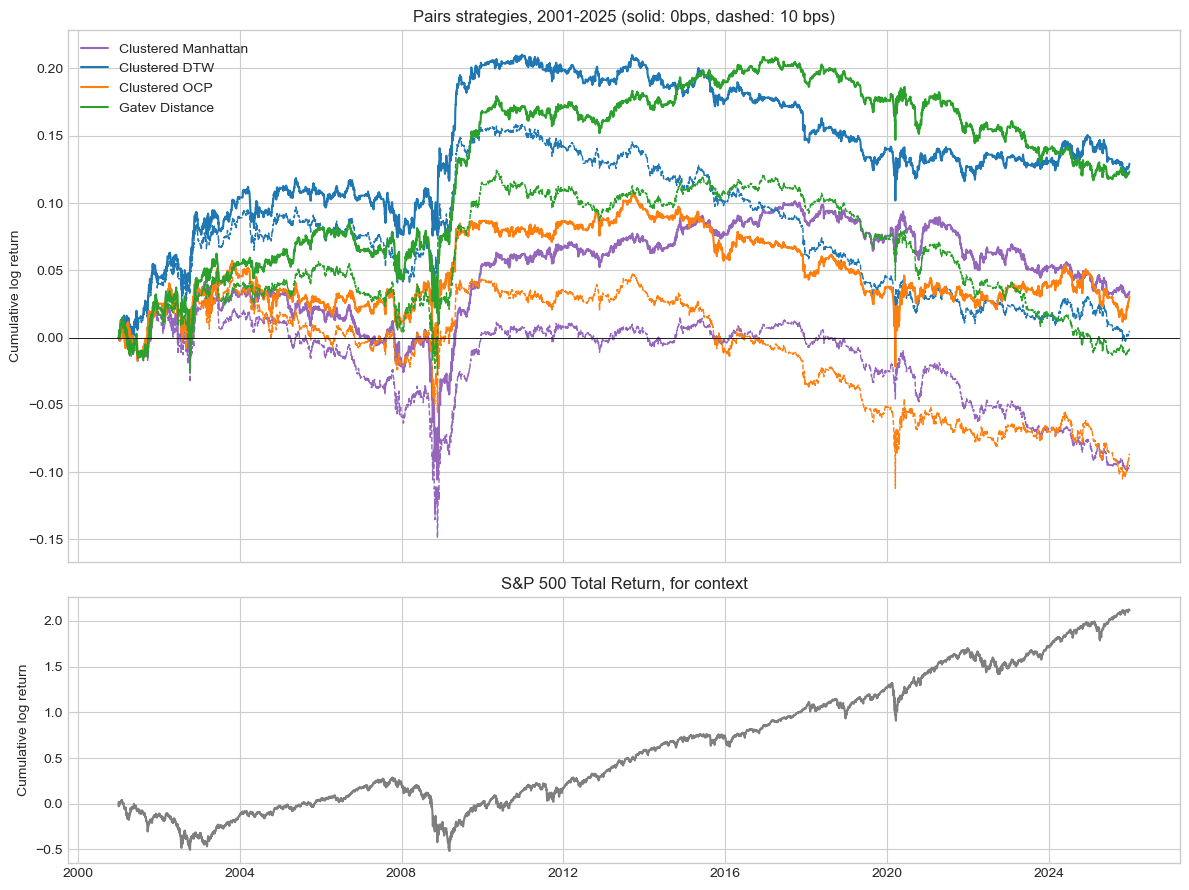

In [35]:
# Stitch the 50 trading periods into one daily series per method and cost level
all_ret = pd.concat([returns[w['window']] for w in windows]).sort_index()
assert all_ret.index.is_unique, 'Overlapping trading days between windows'
print(f'Stitched returns: {all_ret.shape[0]:,} trading days, '
      f'{all_ret.index[0].date()} to {all_ret.index[-1].date()}')

# Naive buy-and-hold (context only): index log returns, and excess over the T-bill for Sharpe
bench_lr = np.log(bench/bench.shift(1)).reindex(all_ret.index)
naive_excess = bench_lr - rf_daily.reindex(all_ret.index)

def perf(raw, excess=None):
    excess = raw if excess is None else excess
    cum = raw.cumsum()
    max_dd = (cum - cum.cummax()).min()
    ann_ret = raw.mean() * TRADING_DAYS
    downside = np.sqrt((excess.clip(upper=0) ** 2).mean())
    return {'ann_return': ann_ret,
            'ann_vol': raw.std() * np.sqrt(TRADING_DAYS),
            'sharpe': excess.mean() / excess.std() * np.sqrt(TRADING_DAYS),
            'sortino': excess.mean() / downside * np.sqrt(TRADING_DAYS),
            'max_drawdown': max_dd,
            'calmar': ann_ret / abs(max_dd) if max_dd < 0 else np.nan,
            'total_log_return': cum.iloc[-1]}

rows = []
for c in COST_LEVELS_BPS:
    for m in METHODS:
        rows.append({'cost_bps': c, 'model': LABELS[m], **perf(all_ret[f'{m}_{c}'])})
rows.append({'cost_bps': np.nan, 'model': LABELS['Naive'], **perf(bench_lr, naive_excess)})
results = pd.DataFrame(rows)
results.to_csv(f'results_{TAG}.csv', index=False)
show = results[results['cost_bps'].isin([0,10]) | results['cost_bps'].isna()]
print(show.to_string(index=False))

# Cumulative performance: pairs strategies on top, the index below for context
fig, axes = plt.subplots(2, 1, figsize=(12,9), sharex=True, gridspec_kw={'height_ratios': [2,1]})
for m in METHODS:
    axes[0].plot(all_ret[f'{m}_0'].cumsum(), label=LABELS[m], color=COLORS[m], lw=1.5)
    axes[0].plot(all_ret[f'{m}_10'].cumsum(), color=COLORS[m], lw=1, ls='--')
axes[0].axhline(0, color='black', lw=0.6)
axes[0].set_ylabel('Cumulative log return')
axes[0].set_title('Pairs strategies, 2001-2025 (solid: 0bps, dashed: 10 bps)')
axes[0].legend(loc='upper left')
axes[1].plot(bench_lr.cumsum(), color=COLORS['Naive'], label=LABELS['Naive'])
axes[1].set_ylabel('Cumulative log return')
axes[1].set_title('S&P 500 Total Return, for context')
plt.tight_layout()
plt.savefig(f'cumulative_performance_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()    

In [36]:
# Planned tests:
# 1. Sharpe differences for the three planned comparisons, block bootstrap
# 2. Each model's Sharpe with a bootstrap interval
# 3. alpha above zero for the clustered models
from scipy import stats

def sharpe_ann(M):
    return M.mean(axis=0) / M.std(axis=0, ddof=1) * np.sqrt(TRADING_DAYS)

def boot_sharpes(M):
    rng = np.random.default_rng(BOOT_SEED)         # Same re-sample for every cost-level
    n = len(M)
    nb = int(np.ceil(n / BLOCK_DAYS))
    out = np.empty((N_BOOT, M.shape[-1])) 
    for b in range(N_BOOT):
        starts = rng.integers(0, n - BLOCK_DAYS + 1, nb)
        idx = (starts[:, None] + np.arange(BLOCK_DAYS)).ravel()[:n]
        out[b] = sharpe_ann(M[idx])
    return out

pos = {m: i for i, m in enumerate(METHODS)}
comp_rows, single_rows = [], []
for c in COST_LEVELS_BPS:
    M = all_ret[[f'{m}_{c}' for m in METHODS]].values
    obs, boot = sharpe_ann(M), boot_sharpes(M)
    for m in METHODS:
        i = pos[m]
        single_rows.append({'cost_bps': c, 'model': LABELS[m], 'sharpe': obs[i],
                             'ci_low': np.percentile(boot[:, i], 2.5),
                             'ci_high': np.percentile(boot[:, i], 97.5)})
    block = []
    for a,b in PLANNED_COMPARISONS:
        d = boot[:, pos[a]] - boot[:, pos[b]]
        block.append({'cost_bps': c, 'comparison': f'{LABELS[a]} vs {LABELS[b]}',
                      'sharpe_diff': obs[pos[a]] - obs[pos[b]],
                      'ci_low': np.percentile(d, 2.5), 'ci_high': np.percentile(d, 97.5),
                      'p_raw': min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
    p_bh = multipletests([r['p_raw'] for r in block], method='fdr_bh')[1]
    for r, q in zip(block, p_bh):
        r['p_bh'] = q
    comp_rows += block

comp_df = pd.DataFrame(comp_rows)
single_df = pd.DataFrame(single_rows)
print('Planned comparisons (Sharpe difference, first minus second):')
print(comp_df.to_string(index=False))
print('\nEach model\'s Sharpe ratio with a 95% bootstrap interval:')
print(single_df.to_string(index=False))

# Alpha clustered models' daily returns regressed on the S&P 500's excess returns (Newey-west errors)
mkt = naive_excess.rename('market')
alpha_rows = []
for c in COST_LEVELS_BPS: 
    for m in ['MAN', 'DTW', 'OCP']:
        fit = sm.OLS(all_ret[f'{m}_{c}'], sm.add_constant(mkt), missing='drop').fit(
            cov_type='HAC', cov_kwds={'maxlags': BLOCK_DAYS})
        t = fit.tvalues['const']
        alpha_rows.append({'cost_bps': c, 'model': LABELS[m],
                           'alpha_annual': fit.params['const'] * TRADING_DAYS,
                           't_alpha': t, 'p_one_sided': 1 - stats.t.cdf(t, fit.df_resid),
                           'beta': fit.params['market']})
alpha_df = pd.DataFrame(alpha_rows)
print('\nAlpha above zero (one-sided test):')
print(alpha_df.to_string(index=False))

comp_df.to_csv(f'planned_comparisons_{TAG}.csv', index=False)
single_df.to_csv(f'sharpe_intervals_{TAG}.csv', index=False)
alpha_df.to_csv(f'alpha_tests_{TAG}.csv', index=False)   

Planned comparisons (Sharpe difference, first minus second):
 cost_bps                            comparison  sharpe_diff  ci_low  ci_high  p_raw   p_bh
        0 Clustered Manhattan vs Gatev Distance      -0.1553 -0.3226   0.0130 0.0676 0.2028
        0  Clustered DTW vs Clustered Manhattan       0.1633 -0.1583   0.4769 0.3264 0.3264
        0        Clustered OCP vs Clustered DTW      -0.1683 -0.4279   0.0843 0.1736 0.2604
        5 Clustered Manhattan vs Gatev Distance      -0.1477 -0.3134   0.0198 0.0824 0.2472
        5  Clustered DTW vs Clustered Manhattan       0.1629 -0.1569   0.4751 0.3228 0.3228
        5        Clustered OCP vs Clustered DTW      -0.1602 -0.4220   0.0924 0.1912 0.2868
       10 Clustered Manhattan vs Gatev Distance      -0.1400 -0.3047   0.0248 0.0940 0.2820
       10  Clustered DTW vs Clustered Manhattan       0.1624 -0.1545   0.4745 0.3172 0.3172
       10        Clustered OCP vs Clustered DTW      -0.1519 -0.4145   0.1007 0.2112 0.3168
       20 Clustered

In [ ]:
# Diagnostics: k choices, how often clustering changed the selection, shared pairs, trading activity
diag = []
for w in windows:
    s = selection[w['window']]
    sets = {m: {frozenset(p) for p in s[m]['pairs']} for m in METHODS}
    row = {'window': w['window'], 'n_stocks': s['n_stocks']}
    for m in ['MAN', 'DTW', 'OCP']:
        row[f'k_{m}'] = s[m]['k']
        row[f'agree_{m}'] = s[m]['agree']
        row[f'overlap_{m}'] = s[m]['overlap']
    for a,b in [('MAN','GATEV'), ('DTW','MAN'),('OCP','DTW'), ('DTW','GATEV')]:
        row[f'shared_{a}_{b}'] = len(sets[a] & sets[b])
    for m in METHODS:
        counts = pd.Series([t for p in s[m]['pairs'] for t in p]).value_counts()
        row[f'maxrepeats_{m}'] = int(counts.max())
        row[f'trips_{m}'] = s[m]['round_trips']
    diag.append(rows)
diag_df = pd.DataFrame(diag)
diag_df.to_csv(F'diagnostics_by_window_{TAG}.csv', index=False)

print('Chosen k and index agreement across all 50 windows:')
for m in ['MAN', 'DTW', 'OCP']:
    print(f"   {LABELS[m}: k {diag_df[f'k_{m}'].value_counts().to_dict()},"
          f"indices agreeing {diag_df[f'agree_{m}'].value_counts().to_dict()}")

print('\nPairs that would have been chosen without clustering (of 20):')
for m in ['MAN','DTW','OCP']:
    o = diag_df[f'overlap_{m}']
    print(f"   {LABELS[m]}: average {o.mean():.1f}, windows at 20 of 20: {(o == N_PAIRS).sum()} of {len(o)}")

print('\nPairs shared between methods (of 20), per window:')
for a, b in [('MAN', 'GATEV'), ('DTW','MAN'), ('OCP', 'DTW'), ('DTW', 'GATEV')]:
    s_ = diag_df[f'shared_{a}_{b}']
    print(f"   {LABELS[a]} and {LABELS[b]}: average {s_.mean():.1f}, range {s_.min()} to {s_.max()}")

print('\nTrading activity and concentration, per window:')
for m in METHODS:
    print(f"    {LABELS[m]}: round trips average {diag_df[f'trips_{m}'].mean():.1f},"
          f"most pairs one stock appears in: average {diag_df[f'maxrepeat_{m}'].mean():.1f}, "
          f"max {diag_df[f'maxrepeeat_{m}'].
        
